<a href="https://colab.research.google.com/github/Stephanie490/Data-201-Project-1/blob/main/Project_1_Tonge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Part 1:

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
heart = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/heart.csv")
heart.head()

Mounted at /content/drive


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# Importing any thing that may be needed
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.datasets import load_iris
from sklearn.metrics import mean_squared_error, roc_auc_score

In [ ]:
heart.shape

(1025, 14)

1. Each row represents a patient and their characteristics like age, cholesterol, etc. The response variable is "target". The classes are  0 = "no heart disease" and 1 = "heart disease"
2. Predictors that could be useful include age, trestbps(resting blood pressure mmHg), chol(cholesterol), and thalach(Maximum heart rate acheived)
3. 526 cases have heart disease and 499 do not have heart disease. The classes are not perfectly even, but there is no drastic imbalance
4. In this case a false positive would mean that the model predicts heart disease, when the patient actually does not have it. A false negative would mean the model predicted no heart disease, when the patient actually has it.
5. A false negative would mean missing a true heart disease diagnosis, leaving the patient without timely treatment and putting them at serious risk. For that reason, I am more concerned about maximizing false positive and minimizing false negatives. This is because the consequences of a miss is more detrimental than the consequences of false alarms.

In [ ]:
heart['target'].value_counts()


,count
target,
1,526
0,499


Part 2:

1. The predictors(age, trestbps. chol, and thalach) have have a somewhat similar range. Nothing is drastically higher than the other so I do not have to scale. As seen earlier my response variable is slightly imbalanced
2. There are no NAs, so I do not have to take take any further steps
3. 1 = Patient has heart disease. 0 = Patient has no heart disease. Dataset is already in 0s and 1s
4. Split the data
5. As mentioned previously I do not think scaling is need in this dataset



In [ ]:
# Summary code
heart[["trestbps", "chol", "age", "thalach"]].describe()

,trestbps,chol,age,thalach
count,1025.000000,1025.00000,1025.000000,1025.000000
mean,131.611707,246.00000,54.434146,149.114146
std,17.516718,51.59251,9.072290,23.005724
min,94.000000,126.00000,29.000000,71.000000
25%,120.000000,211.00000,48.000000,132.000000
50%,130.000000,240.00000,56.000000,152.000000
75%,140.000000,275.00000,61.000000,166.000000
max,200.000000,564.00000,77.000000,202.000000


In [ ]:
heart.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
# SPLITTING
#set features and target
X = heart[['trestbps', 'chol', 'age', 'thalach']]
y = heart['target']

# Split the data into training and final test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #75% and 25%
    stratify=y,   #keeps the proportion of default/non-default cases similar
    random_state=0  #makes the split reproducible
    )

Part 3

In [ ]:
# -----------------------------
# KNN: tune k and weights
# -----------------------------

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [1, 5, 11, 51, 81],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=5,
    scoring='roc_auc'
)

grid_knn.fit(X_train, y_train)


# -----------------------------
# Logistic Regression: tune C
# -----------------------------

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logreg_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    logreg,
    logreg_grid,
    cv=5,
    scoring='roc_auc'
)

grid_lr.fit(X_train, y_train)


# -----------------------------
# LDA: evaluate with CV
# -----------------------------

lda = LinearDiscriminantAnalysis()

lda_scores = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)


# -----------------------------
# QDA: evaluate with CV
# -----------------------------

qda = QuadraticDiscriminantAnalysis()

qda_scores = cross_val_score(
    qda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)


# -----------------------------
# Compare results
# -----------------------------

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))

print("\nLogistic Regression best parameters:", grid_lr.best_params_)
print("Logistic Regression best CV ROC-AUC:", round(grid_lr.best_score_, 4))

print("\nLDA mean CV ROC-AUC:", round(lda_scores.mean(), 4))

print("QDA mean CV ROC-AUC:", round(qda_scores.mean(), 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 81, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC-AUC: 0.9966

Logistic Regression best parameters: {'logisticregression__C': 0.01}
Logistic Regression best CV ROC-AUC: 0.7448

LDA mean CV ROC-AUC: 0.7442
QDA mean CV ROC-AUC: 0.7587


Graph showing K -> Cross-validation performance

In [ ]:
#Tested slightly higher values
k_values = [1, 5, 11, 81, 85]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5
    )

    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.9570155334861218), np.float64(0.7279178338001867), np.float64(0.6888124946948476), np.float64(0.7083778966131907), np.float64(0.695373907138613)]


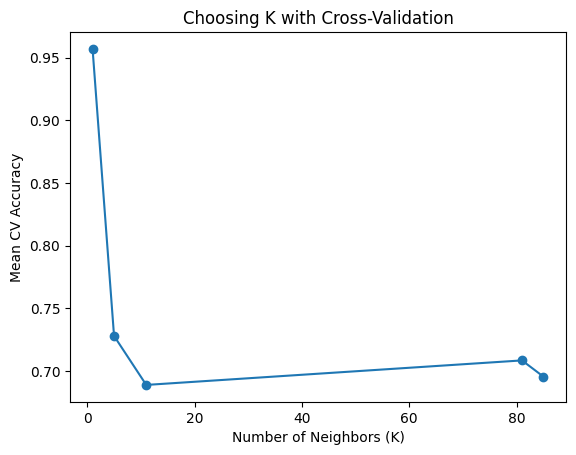

In [ ]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

Fit Final KNN Mode K = 5:
The highest score what seen in k value = 1. However, I cannot use it has 100% accuracy regardless of the actual decision. Therefore, I used the value with the 2nd highest score which was k = 5

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

#fit
best_knn.fit(X_train, y_train)

#predict
best_knn_pred = best_knn.predict(X_test)

#evaluate
accuracy_score(y_test, best_knn_pred)

0.7509727626459144

Logistic Regression - Predictions and Probability

In [ ]:
logreg.fit(X_train, y_train) # Did this because kept getting "NotFitted Error"

prob_default = logreg.predict_proba(X_test)[:, 1]
prob_default

array([0.40184116, 0.58727855, 0.73286224, 0.65964312, 0.79433673,
       0.37923854, 0.42712777, 0.20151705, 0.60995806, 0.52330974,
       0.40694858, 0.8532134 , 0.23813152, 0.74014707, 0.50642148,
       0.28669888, 0.09868689, 0.51205974, 0.73980659, 0.4624646 ,
       0.34957159, 0.46732094, 0.66961112, 0.77768797, 0.49415828,
       0.84630333, 0.41467439, 0.34440773, 0.58506114, 0.40184116,
       0.63207449, 0.11131583, 0.65964312, 0.57418955, 0.42621617,
       0.79320991, 0.45870518, 0.60285472, 0.43754992, 0.33384995,
       0.53900306, 0.45870518, 0.40694858, 0.16627136, 0.64164936,
       0.33906858, 0.10475628, 0.52351751, 0.8532134 , 0.46732094,
       0.30604071, 0.75132769, 0.9088999 , 0.5756951 , 0.73870829,
       0.78865495, 0.32972324, 0.56798024, 0.88350096, 0.51120001,
       0.37667373, 0.77768797, 0.69237327, 0.76369053, 0.78773057,
       0.84630333, 0.12912792, 0.47484905, 0.41660556, 0.57139028,
       0.77138426, 0.85003062, 0.34248847, 0.09685176, 0.18775

In [ ]:
pred_30 = logreg.predict(X_test)

In [ ]:
# Caculating probability
results = X_test.copy()

results["Actual"] = y_test.values
results["P(Default)"] = prob_default
results["Prediction_0.30"] = pred_30 # Lower threshold more false positives

In [ ]:
results.head(15)
results["Prediction_0.30"] = (
    results["P(Default)"] >= 0.30
).astype(int)

results.head()

,trestbps,chol,age,thalach,Actual,P(Default),Prediction_0.30
385,110,175,51,123,1,0.401841,1
519,148,203,61,161,0,0.587279,1
366,112,230,58,165,0,0.732862,1
655,110,235,41,153,1,0.659643,1
324,130,245,48,180,1,0.794337,1


Part 4

Confusion matrix:

My decision threshold will be set to 0.3 because I need to minimize false negatives. Lowering the thresholdto a value below .5 increases false positives. Therefore, choosing 0.3 aligns with my goal of reducing false negatives while accepting the trade‑off of higher false positives

LDA Confusion Matrix

In [ ]:
#Fit the final model using all training data
lda.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
lda.classes_

#get the probability of defaulting "Yes"
prob_yes_lda = lda.predict_proba(X_test)[:, 1]

prob_yes_lda[:10]

array([0.40462919, 0.59530714, 0.74117095, 0.66698914, 0.8024889 ,
       0.38233702, 0.4318214 , 0.20055595, 0.61797051, 0.529513  ])

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Threshold = 30% (1 = Yes, 0 = No)
pred_30 = np.where(
    prob_yes_lda >= 0.30,
    1,
    0
)
# ^ Had to change it to numeric because my dataset has 0s and 1s, instead of "Yes" and "No"

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 47  78]
 [ 11 121]]
TN: 47
FP: 78
FN: 11
TP: 121


QDA Confusion Matrix

In [ ]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# Fit the final model using all training data
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

# Check the classes
qda.classes_

# Get the probability of defaulting "Yes"
prob_yes_qda = qda.predict_proba(X_test)[:, 1]

prob_yes_qda[:10]

array([0.28593423, 0.5706495 , 0.57981942, 0.73881613, 0.84055133,
       0.35972213, 0.52656284, 0.06948269, 0.61632797, 0.57245653])

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Threshold = 30% (1 = Yes, 0 = No)
pred_30 = np.where(
    prob_yes_qda >= 0.30,
    1,
    0
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 51  74]
 [ 15 117]]
TN: 51
FP: 74
FN: 15
TP: 117


KNN Confusion Matrix

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Fit the final model using all training data
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Check the classes
knn.classes_

# Get the probability of defaulting "Yes"
prob_yes_knn = knn.predict_proba(X_test)[:, 1]

prob_yes_knn[:10]

array([0.40462919, 0.59530714, 0.74117095, 0.66698914, 0.8024889 ,
       0.38233702, 0.4318214 , 0.20055595, 0.61797051, 0.529513  ])

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Threshold = 30% (1 = Yes, 0 = No)
pred_30 = np.where(
    prob_yes_knn >= 0.30,
    1,
    0
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 75  50]
 [ 12 120]]
TN: 75
FP: 50
FN: 12
TP: 120


Logistic Regression Confusion Matrix

In [ ]:
# Fit the final model using all training data
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# Check the classes (e.g., ['No', 'Yes'])
log_reg.classes_

# Get the probability of defaulting "Yes"
prob_yes_log = log_reg.predict_proba(X_test)[:, 1]

prob_yes_log[:10]

array([0.40025714, 0.58859435, 0.73498586, 0.65964387, 0.79598126,
       0.37747837, 0.42653563, 0.19907096, 0.61127833, 0.52239685])

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Threshold = 30% (1 = Yes, 0 = No)
pred_30 = np.where(
    prob_yes_log >= 0.30,
    1,
    0
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 49  76]
 [ 11 121]]
TN: 49
FP: 76
FN: 11
TP: 121


LDA Metrics

In [ ]:
#threshold to 30%
pred_30 = np.where(
    prob_yes_lda >= 0.30,
    1,
    0
)

#CM
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

#metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[ 47  78]
 [ 11 121]]
Accuracy: 0.6536964980544747
Precision: 0.6080402010050251
Recall: 0.9166666666666666
Specificity: 0.376
F1: 0.7311178247734139


QDA Metrics

In [ ]:
#threshold to 30%
pred_30 = np.where(
    prob_yes_qda >= 0.30,
    1,
    0
)

#CM
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

#metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[ 51  74]
 [ 15 117]]
Accuracy: 0.6536964980544747
Precision: 0.612565445026178
Recall: 0.8863636363636364
Specificity: 0.408
F1: 0.7244582043343654


KNN Metrics

In [ ]:
#threshold to 30%
pred_30 = np.where(
    prob_yes_knn >= 0.30,
    1,
    0
)

#CM
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

#metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[ 75  50]
 [ 12 120]]
Accuracy: 0.7587548638132295
Precision: 0.7058823529411765
Recall: 0.9090909090909091
Specificity: 0.6
F1: 0.7947019867549668


Logistic Regresion Metrics

In [ ]:
#threshold to 30%
pred_30 = np.where(
    prob_yes_log >= 0.30,
    1,
    0
)

#CM
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

#metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[ 49  76]
 [ 11 121]]
Accuracy: 0.6614785992217899
Precision: 0.6142131979695431
Recall: 0.9166666666666666
Specificity: 0.392
F1: 0.7355623100303952


Part 5

The metrics I am interested in is Recall. In this case, the recall tell us out of all the individuals that have heart disease, how many did the model catch. A high recall would indicate that there are less fase negatives. In other words most patients who truly have heart disease are flagged and can get the treatment the need.
Aditionally, Precision is important since it states whther there are TOO many false alarms AKA people without  heart disease who have flagged as having heart disease.

Part 6

LDA ROC

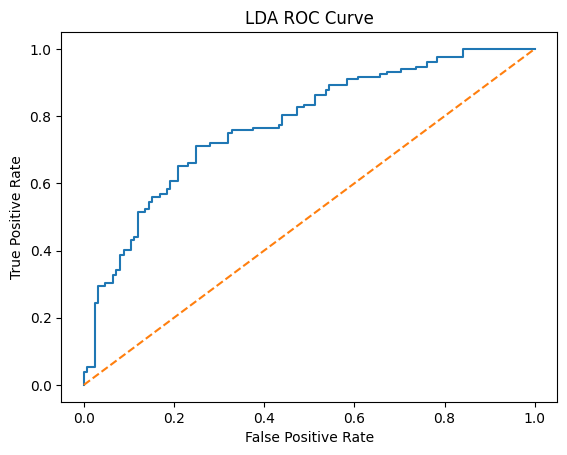

In [ ]:
# ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_lda
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA ROC Curve")

plt.show()

QDA ROC

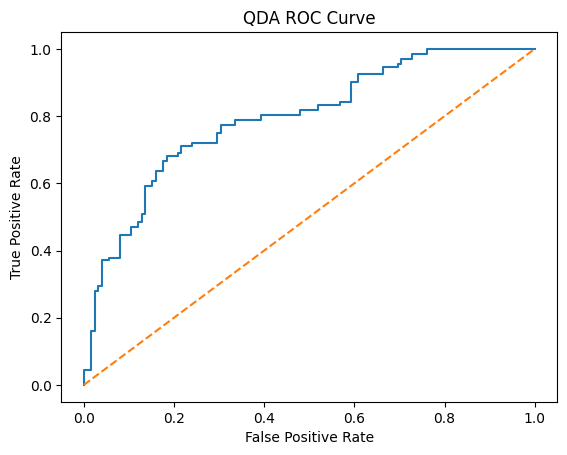

In [ ]:
# ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_qda
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("QDA ROC Curve")

plt.show()

Logistic Regresion ROC

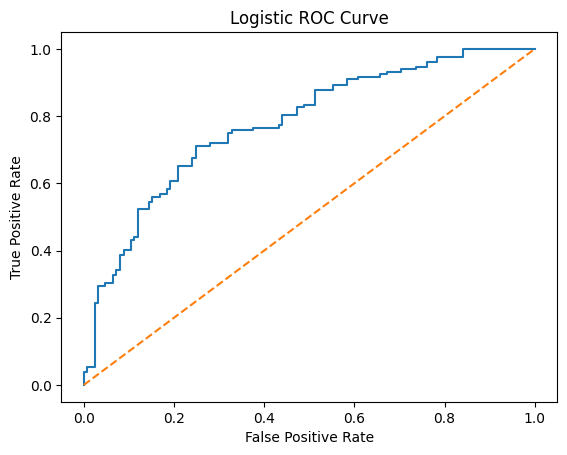

In [ ]:
# ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_log
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic ROC Curve")

plt.show()

KNN ROC

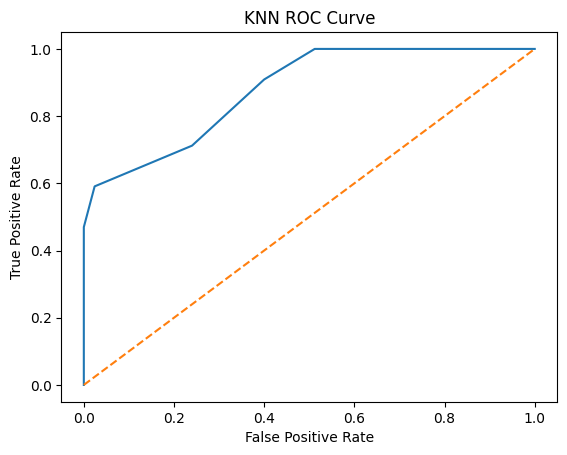

In [ ]:
# ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_knn
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")

plt.show()

LDA AUC

In [ ]:
auc = roc_auc_score(
    y_test_binary,
    prob_yes_lda
)

print("LDA AUC:", auc)

LDA AUC: 0.7763030303030303


QDA AUC

In [ ]:
auc = roc_auc_score(
    y_test_binary,
    prob_yes_qda
)

print(" QDA AUC:", auc)

 QDA AUC: 0.7942424242424242


KNN AUC

In [ ]:
auc = roc_auc_score(
    y_test_binary,
    prob_yes_knn
)

print("KNN AUC:", auc)

KNN AUC: 0.8780606060606061


Logistic Regression AUC

In [ ]:
auc = roc_auc_score(
    y_test_binary,
    prob_yes_log
)

print("Logistic AUC:", auc)

Logistic AUC: 0.7767272727272727


Part 7

1. Among the models, LDA produced the lowest AUC at 0.776, followed closely by logistic regression at 0.777. KNN achieved the highest AUC at 0.88, suggesting it may be the strongest overall classifier. Across all models, the ROC curves showed a consistently rising true positive rate. In this case it shows most patients with heart disease are correctly identified as positive.
2. I would choose the KNN model because it demonstrates the strongest overall performance. It has the highest AUC and accuracy, and the recall values is 91%, meaning it correctly identifies most patients who truly have heart disease. This is essential, as catching positive cases early ensures patients receive timely treatment. KNN also has the highest precision at 71%, compared to 61% for the other models, indicating fewer false alarms. In other words, patients without heart disease are less likely to be incorrectly flagged, reducing unnecessary stress, panic, and medical costs.
3. I think there is a limitation in the predictors I used. For example, I did not do any of the categorical features like chest pain. If I added one of those variables my model may have been stronger
4. Some more data on individual's daily lifestyle could have been helpful. For example, their diet like how much sodium or sugar they consume in a day. Additionally, alchol use and smoking status would be useful since those factors could contribute to heart disease


Visualizations Used in Presentation

/tmp/ipykernel_1260/2413573877.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='target', data=heart, palette=['#4C72B0', '#55A868'])


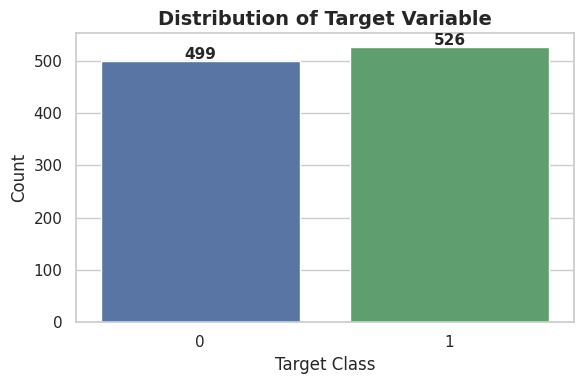

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Create the figure
plt.figure(figsize=(6, 4))

# Plot the distribution of the target variable
ax = sns.countplot(x='target', data=heart, palette=['#4C72B0', '#55A868'])

# Add labels and title
plt.title('Distribution of Target Variable', fontsize=14, fontweight='bold')
plt.xlabel('Target Class', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add exact counts on top of each bar for clarity
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Show the plot
plt.tight_layout()
plt.show()

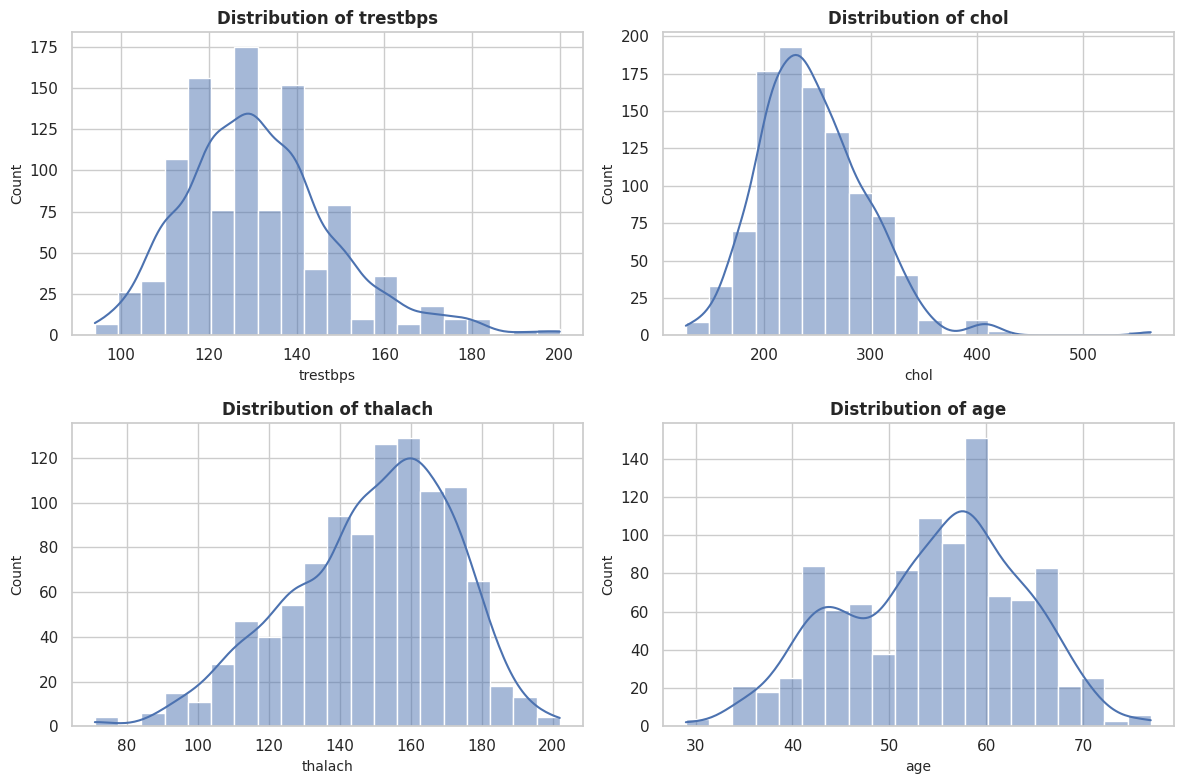

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Define the list of continuous variables you want to plot
features = ['trestbps', 'chol', 'thalach', 'age']

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
axes = axes.flatten()  # Flatten to easily loop through them

# Loop through each feature and plot its distribution
for i, col in enumerate(features):
    sns.histplot(
        data=heart,
        x=col,
        kde=True,          # Adds a smooth density curve line
        ax=axes[i],
        color='#4C72B0',
        bins=20
    )
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()